In [1]:
# Import required libraries
import sys
#sys.path.append(stm_graph_path)
#import stm_graph
import os
import pandas as pd
import numpy as np
import datetime
from datetime import timedelta
import matplotlib.pyplot as plt
import contextily as ctx

# Define the data and output directories
DATA_DIR = ""
CRASH_DATASET = "Motor_Vehicle_Collisions_from2016.csv"
REDLIGHT_DATASET = "Open_Parking_and_Camera_Violations_20261008.csv"

OUTPUT_DIR = ""

In [23]:
# Step 1: Read the raw data
print(f"Reading raw crash data from {CRASH_DATASET}")
crash_df = pd.read_csv(CRASH_DATASET, low_memory=False)

print(f"Reading raw red light incident data from {REDLIGHT_DATASET}")
redlight_df = pd.read_csv(REDLIGHT_DATASET, low_memory=False)


Reading raw crash data from Motor_Vehicle_Collisions_from2016.csv
Reading raw red light incident data from Open_Parking_and_Camera_Violations_20261008.csv


In [24]:
base_crash_df = crash_df.copy(deep=True)
base_redlight_df = redlight_df.copy(deep=True)

In [44]:
day_names = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

crash_df['CRASH DATE'] = base_crash_df['CRASH DATE'].map(lambda x: day_names[datetime.datetime.strptime(x, '%m/%d/%Y').weekday()])
crash_df['CRASH TIME'] = base_crash_df['CRASH TIME'].map(lambda x: str(x)[:-3]).astype(int)

#redlight_df['CRASH DATE'] = pd.to_datetime(redlight_df['CRASH DATE'])
redlight_df['Violation Time'] = base_redlight_df['Violation Time'].map(lambda x: str(x)[:-4] if x[-1] ==  "A" else int(str(x)[:-4])+12).astype(int)
redlight_df['Violation Time'] = base_redlight_df['Violation Time'].map(lambda x: 12 if x == 24 else 0 if x == 12 else x)
redlight_df['Issue Date'] = base_redlight_df['Issue Date'].map(lambda x: day_names[datetime.datetime.strptime(x, '%m/%d/%Y').weekday()])




# Display basic information about the dataset
print(f"Dataset shape: {base_crash_df.shape}")
print("\nColumn names:")
print(base_crash_df.columns.tolist())
print("\nSample data:")
base_crash_df.head(50)

Dataset shape: (1540753, 29)

Column names:
['CRASH DATE', 'CRASH TIME', 'BOROUGH', 'ZIP CODE', 'LATITUDE', 'LONGITUDE', 'LOCATION', 'ON STREET NAME', 'CROSS STREET NAME', 'OFF STREET NAME', 'NUMBER OF PERSONS INJURED', 'NUMBER OF PERSONS KILLED', 'NUMBER OF PEDESTRIANS INJURED', 'NUMBER OF PEDESTRIANS KILLED', 'NUMBER OF CYCLIST INJURED', 'NUMBER OF CYCLIST KILLED', 'NUMBER OF MOTORIST INJURED', 'NUMBER OF MOTORIST KILLED', 'CONTRIBUTING FACTOR VEHICLE 1', 'CONTRIBUTING FACTOR VEHICLE 2', 'CONTRIBUTING FACTOR VEHICLE 3', 'CONTRIBUTING FACTOR VEHICLE 4', 'CONTRIBUTING FACTOR VEHICLE 5', 'COLLISION_ID', 'VEHICLE TYPE CODE 1', 'VEHICLE TYPE CODE 2', 'VEHICLE TYPE CODE 3', 'VEHICLE TYPE CODE 4', 'VEHICLE TYPE CODE 5']

Sample data:


,CRASH DATE,CRASH TIME,BOROUGH,ZIP CODE,LATITUDE,LONGITUDE,LOCATION,ON STREET NAME,CROSS STREET NAME,OFF STREET NAME,...,CONTRIBUTING FACTOR VEHICLE 2,CONTRIBUTING FACTOR VEHICLE 3,CONTRIBUTING FACTOR VEHICLE 4,CONTRIBUTING FACTOR VEHICLE 5,COLLISION_ID,VEHICLE TYPE CODE 1,VEHICLE TYPE CODE 2,VEHICLE TYPE CODE 3,VEHICLE TYPE CODE 4,VEHICLE TYPE CODE 5
0,01/02/2016,0:05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Unspecified,NaN,NaN,NaN,3364091,SPORT UTILITY / STATION WAGON,PASSENGER VEHICLE,NaN,NaN,NaN
1,01/02/2016,11:08,NaN,NaN,NaN,NaN,NaN,EAST 23 STREET,FDR DRIVE EAST SERVICE ROAD,NaN,...,NaN,NaN,NaN,NaN,3364045,MOTORCYCLE,NaN,NaN,NaN,NaN
2,01/02/2016,19:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Driver Inattention/Distraction,NaN,NaN,NaN,3364135,SPORT UTILITY / STATION WAGON,PASSENGER VEHICLE,NaN,NaN,NaN
3,01/02/2016,12:35,BROOKLYN,11229.0,40.599803,-73.947594,"(40.5998026, -73.9475941)",AVENUE U,EAST 24 STREET,NaN,...,Unspecified,NaN,NaN,NaN,3363757,PASSENGER VEHICLE,SPORT UTILITY / STATION WAGON,NaN,NaN,NaN
4,01/02/2016,16:00,BROOKLYN,11235.0,40.591685,-73.940201,"(40.5916853, -73.9402012)",NOSTRAND AVENUE,AVENUE Y,NaN,...,NaN,NaN,NaN,NaN,3363758,SPORT UTILITY / STATION WAGON,NaN,NaN,NaN,NaN
5,01/02/2016,10:35,NaN,NaN,NaN,NaN,NaN,CORNAGA AVENUE,BEACH 19 STREET,NaN,...,Unspecified,Unspecified,NaN,NaN,3363877,SPORT UTILITY / STATION WAGON,SPORT UTILITY / STATION WAGON,SPORT UTILITY / STATION WAGON,NaN,NaN
6,01/02/2016,8:40,QUEENS,11413.0,40.672417,-73.744848,"(40.6724166, -73.7448477)",137 AVENUE,228 STREET,NaN,...,Unspecified,Unspecified,NaN,NaN,3364297,PASSENGER VEHICLE,PASSENGER VEHICLE,PASSENGER VEHICLE,NaN,NaN
7,01/02/2016,12:05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,85 ST TRANSVERSE ROAD,...,Unspecified,NaN,NaN,NaN,3363644,LARGE COM VEH(6 OR MORE TIRES),PASSENGER VEHICLE,NaN,NaN,NaN
8,01/02/2016,17:00,BROOKLYN,11237.0,40.704091,-73.927643,"(40.7040907, -73.9276429)",MELROSE STREET,KNICKERBOCKER AVENUE,NaN,...,Unspecified,NaN,NaN,NaN,3364251,UNKNOWN,LIVERY VEHICLE,NaN,NaN,NaN
9,01/02/2016,18:00,QUEENS,11370.0,40.766359,-73.887554,"(40.766359, -73.8875543)",82 STREET,23 AVENUE,NaN,...,Unspecified,NaN,NaN,NaN,3368432,PASSENGER VEHICLE,PASSENGER VEHICLE,NaN,NaN,NaN


<Axes: xlabel='CRASH TIME'>

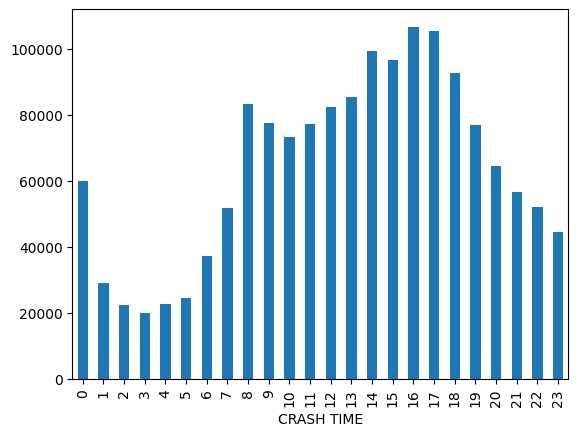

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

crash_df['CRASH TIME'].value_counts().sort_index().plot.bar()

<Axes: xlabel='Violation Time'>

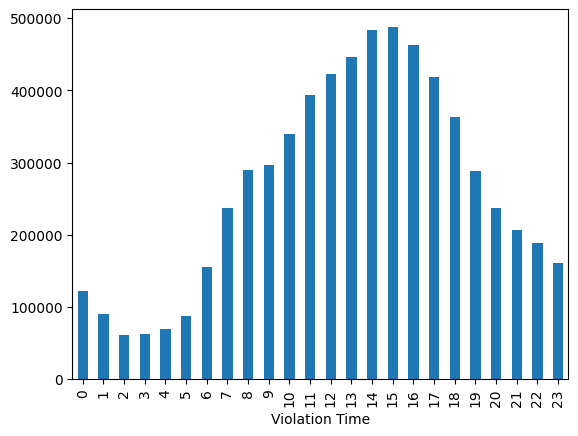

In [84]:
redlight_df['Violation Time'].value_counts().sort_index().plot.bar()


<Axes: >

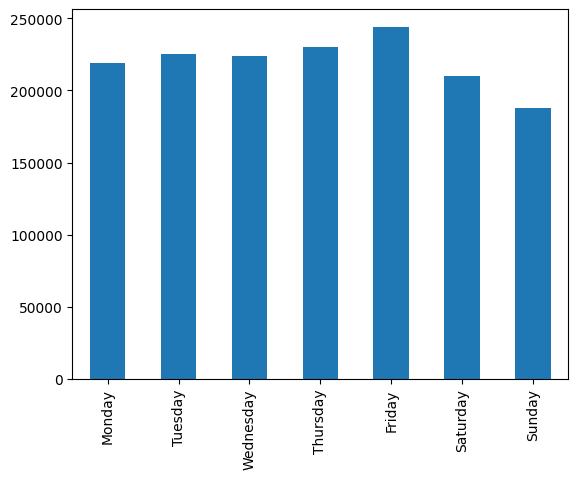

In [45]:
crash_df['CRASH DATE'].value_counts().reindex(day_names).plot.bar()

<Axes: >

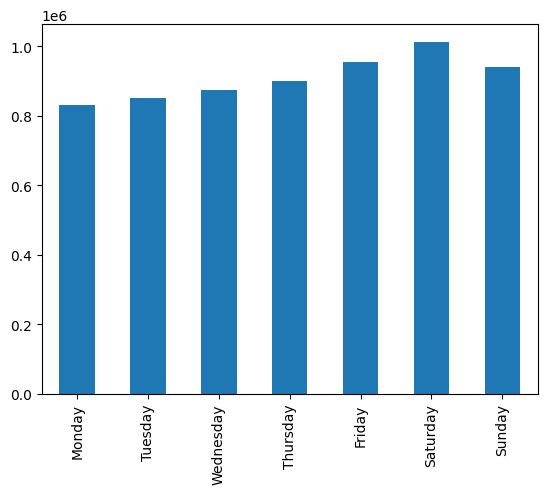

In [46]:
redlight_df['Issue Date'].value_counts().reindex(day_names).plot.bar()
